# Did the bus actually stop? One-day analysis (v5)

**Question.** For each scheduled bus call on the one day we have data for: did the bus stop at the stop, or drive past?

**Data.** One 24-hour window (the span of the real-time snapshots). GTFS is the timetable, `stop_visits` (SIRI ET) is when the system recorded each call, and `vehicle_positions` is the GPS.

**What changed from v4**

- `vehicle_positions.speed` is empty in the whole file, so v4's stopped/passed test could never fire: every event with a nearby ping ended up as `near_no_speed`. Speed is now derived from consecutive pings of the same vehicle.
- v4 matched GPS to a stop by line + time only. That can pick up a *different* bus on the same line, or one far away (likely where the ">1 km nearest ping" rows came from). Now each trip is first matched to one specific vehicle, and only that vehicle's track is used.
- The multi-date logic and the side analyses (alerts, shapes, route-type checks, ferry checks, delays) are gone. The cells now run top to bottom with no out-of-order dependencies.

## How to read the result

The ET feed cannot answer the question by itself: it copies one time into both `actual_arrival` and `actual_departure` (so there is no dwell time), and a "recorded" call only says the system registered the bus there. GPS is the only evidence of standing still.

GPS pings arrive about every 30 s, and a bus that stands at a stop for 10–20 s is often between two pings. Speed is measured over those 30 s steps, so even a real stop rarely shows speed 0: the step averages driving and standing. That is why "driving past" is judged against the bus's own usual speed nearby, not a fixed number. The result is a set of evidence levels, not a yes/no:

| `gps_class` | Meaning |
|---|---|
| `stopped_confirmed` | 2+ pings within `NEAR_M` of the stop that look stopped: standing (`SLOW_MS`) or well below the bus's usual speed there (`SLOW_RATIO`) |
| `likely_stopped` | 1 such ping within `NEAR_M` of the stop |
| `likely_passed` | ping(s) within `NEAR_M`, all at or above `FAST_RATIO` of the bus's usual speed |
| `near_unclear` | ping within `NEAR_M`, speed in between (or no usable speed) |
| `no_ping_at_stop` | the bus track exists, but no ping landed within `NEAR_M`: cannot tell |
| `no_gps` | bus matched, but there is a GPS hole at the time of the stop |
| `no_vehicle` | no bus could be matched to the trip |

A bus driving past a stop is normal when nobody is waiting or has asked to get off. "Passed" is not a service failure.

## 0. Setup

In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

DATA_DIR = Path(".")        # folder that holds the .parquet files
OUT_DIR = Path("clean")     # results are written here
OUT_DIR.mkdir(exist_ok=True)
LOCAL_TZ = "Europe/Oslo"

# ---- the stop test: every threshold is here ----
NEAR_M = 30        # a ping this close to the stop (metres) counts as "at the stop"
SLOW_MS = 2.0      # speed at or below this (m/s, about 7 km/h) = standing still
SLOW_RATIO = 0.75  # ...or at or below this share of the bus's usual speed nearby = slowed down for the stop
FAST_RATIO = 0.90  # at or above this share of its usual speed = driving past
MIN_CRUISE_MS = 3  # a usual speed below this (m/s) is too low to judge "relative to usual"
CRUISE_WIN = 11    # usual speed = looked up among the 11 neighbouring step speeds (about 5 minutes of driving)
CRUISE_Q = 0.75    # ...as their 75th percentile: the speed the bus reaches when it is not standing
WIN_S = 60         # look at pings within +-60 s of the recorded stop time
MAX_GAP_S = 90     # pings further apart than this are not joined into a track
MIN_DT_S = 5       # pings closer than this give a noisy speed, so no speed is derived

# ---- matching a vehicle to a trip ----
ASSIGN_MAX_M = 100    # median distance (m) between the bus and the trip's stops at the recorded times
ASSIGN_MIN_STOPS = 3  # ...judged on at least this many stops

EPOCH = pd.Timestamp("1970-01-01", tz="UTC")


def pq_path(name):
    return DATA_DIR / f"{name}.parquet"


def check(label, bad, total=None):
    tail = f" of {total:,}" if total is not None else ""
    print(f"{'OK ' if bad == 0 else 'LOOK'}  {label}: {bad:,}{tail}")

## 1. Timetable (GTFS)

Only what the analysis needs: bus routes, their trips, stop coordinates, and the ordered stop calls of each trip. `occ` numbers repeated calls at the same stop within one trip (loops), so a call is identified by trip + stop + occurrence.

In [2]:
BUS_TYPES = {"3"} | {str(x) for x in range(700, 800)}     # 7xx = bus family in extended GTFS

routes = pd.read_parquet(pq_path("gtfs_routes"), columns=["route_id", "route_short_name", "route_type"])
routes["is_bus"] = routes["route_type"].astype(str).str.strip().isin(BUS_TYPES)
trips = pd.read_parquet(pq_path("gtfs_trips"), columns=["trip_id", "route_id", "service_id"])
stops = (pd.read_parquet(pq_path("gtfs_stops"), columns=["stop_id", "stop_name", "stop_lat", "stop_lon"])
           .drop_duplicates("stop_id"))
for c in ["stop_lat", "stop_lon"]:
    stops[c] = pd.to_numeric(stops[c], errors="coerce")

calendar = pd.read_parquet(pq_path("gtfs_calendar"))
calendar_dates = pd.read_parquet(pq_path("gtfs_calendar_dates"))
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
for c in DAYS:
    calendar[c] = calendar[c].astype(str).str.strip().eq("1")

stop_times = pd.read_parquet(pq_path("gtfs_stop_times"), columns=[
    "trip_id", "stop_id", "arrival_time", "departure_time", "stop_sequence", "pickup_type", "drop_off_type"])

# bus trips only, from here on
bus_trips = trips.merge(routes.loc[routes["is_bus"], ["route_id", "route_short_name"]], on="route_id", how="inner")
st_all = stop_times[stop_times["trip_id"].isin(bus_trips["trip_id"])].copy()
st_all["stop_sequence"] = st_all["stop_sequence"].astype(int)
st_all = st_all.sort_values(["trip_id", "stop_sequence"])
st_all["occ"] = st_all.groupby(["trip_id", "stop_id"]).cumcount()

# some calls are timetabled as "no pick-up and no drop-off", i.e. the bus is not meant to stop there
st_all["sched_no_stop"] = (st_all["pickup_type"].astype(str).str.strip().eq("1")
                           & st_all["drop_off_type"].astype(str).str.strip().eq("1"))

print(f"{routes['is_bus'].sum():,} bus routes | {len(bus_trips):,} bus trips | {len(st_all):,} bus stop calls")
print(f"calls timetabled as 'does not stop': {int(st_all['sched_no_stop'].sum()):,}")
check("stop calls whose stop_id is not in gtfs_stops", (~st_all["stop_id"].isin(stops["stop_id"])).sum(), len(st_all))
check("stop calls without coordinates", st_all["stop_id"].map(stops.set_index("stop_id")["stop_lat"]).isna().sum(), len(st_all))

297 bus routes | 12,628 bus trips | 414,572 bus stop calls
calls timetabled as 'does not stop': 31
OK   stop calls whose stop_id is not in gtfs_stops: 0 of 414,572
OK   stop calls without coordinates: 0 of 414,572


## 2. Real-time stop calls (`stop_visits`)

The feed repeats every call in many snapshots as predictions change. One call = `data_frame_ref` + `journey_ref` + `stop_order`. Per call I keep the newest snapshot, but take `actual_*` from an older snapshot if the newest one lacks it. Ferries are excluded and the rest is checked against the bus allow-list from GTFS.

Only the columns the analysis uses are read (v4 read 21, most of them unused here).

In [3]:
ET_COLS = ["snapshot_time", "data_frame_ref", "journey_ref", "line_ref", "vehicle_mode",
           "journey_cancelled", "call_cancelled", "call_type", "stop_order", "stop_ref",
           "aimed_arrival", "actual_arrival", "aimed_departure", "actual_departure"]

# null-safe: a plain != "ferry" filter would also drop rows whose vehicle_mode is NULL
NOT_FERRY = ds.field("vehicle_mode").is_null() | (ds.field("vehicle_mode") != "ferry")
et = pd.read_parquet(pq_path("stop_visits"), columns=ET_COLS, engine="pyarrow", filters=NOT_FERRY)
print(f"{len(et):,} non-ferry snapshot rows")

# the time span the feed covers = the analysis window
WIN_START, WIN_END = et["snapshot_time"].min(), et["snapshot_time"].max()
print("window (UTC):", WIN_START, "->", WIN_END)
print("window (local):", WIN_START.tz_convert(LOCAL_TZ), "->", WIN_END.tz_convert(LOCAL_TZ))
print("service-date labels in the feed:", sorted(et["data_frame_ref"].dropna().unique()))

9,494,374 non-ferry snapshot rows
window (UTC): 2026-10-24 00:00:15+00:00 -> 2026-10-24 23:59:41+00:00
window (local): 2026-10-24 02:00:15+02:00 -> 2026-10-25 01:59:41+02:00
service-date labels in the feed: ['2026-10-24', '2026-10-25', '2026-10-26', '2026-10-27']


In [4]:
KEY = ["data_frame_ref", "journey_ref", "stop_order"]      # one real call = this key
ACTUALS = ["actual_arrival", "actual_departure"]

et["stop_order"] = pd.to_numeric(et["stop_order"], errors="coerce")
et = et.dropna(subset=KEY + ["stop_ref"]).copy()
et["stop_order"] = et["stop_order"].astype("int64")
for c in ACTUALS:                                          # blank strings are not NaN
    et[c] = et[c].mask(et[c].astype("string").str.strip().eq(""))

et = et.sort_values("snapshot_time", kind="stable")
g = et.groupby(KEY, sort=False)
latest = et.drop_duplicates(KEY, keep="last").set_index(KEY)
last_actuals = g[ACTUALS].last().reindex(latest.index)     # newest non-empty actual per call
latest[ACTUALS] = latest[ACTUALS].fillna(last_actuals)
latest["n_snapshots"] = g.size().reindex(latest.index).to_numpy()
visits = latest.reset_index()
n_rows = len(et)
del et, g, latest, last_actuals
gc.collect()
print(f"{n_rows:,} snapshot rows -> {len(visits):,} distinct calls")

# timestamps: ISO strings with offsets -> UTC
for c in ["aimed_arrival", "actual_arrival", "aimed_departure", "actual_departure"]:
    visits[c] = pd.to_datetime(visits[c], format="ISO8601", utc=True, errors="coerce")

# bus allow-list and known stops
visits = visits.merge(routes[["route_id", "is_bus"]], left_on="line_ref", right_on="route_id", how="left").drop(columns="route_id")
n = len(visits)
visits = visits[visits["is_bus"].fillna(False)]
visits = visits[visits["stop_ref"].isin(stops["stop_id"])].copy()
print(f"kept bus calls at known stops: {len(visits):,} (removed {n - len(visits):,})")


def flag(s):
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1"])


cancelled = flag(visits["journey_cancelled"]) | flag(visits["call_cancelled"])
visits["visit_time"] = visits["actual_departure"].fillna(visits["actual_arrival"])      # the one time the feed gives
visits["visit_status"] = np.select([cancelled, visits["visit_time"].notna()], ["cancelled", "observed"], default="unconfirmed")

# occurrence number of a stop inside a trip, to match GTFS stop calls
visits["occ"] = visits.sort_values("stop_order").groupby(["data_frame_ref", "journey_ref", "stop_ref"]).cumcount()

print(visits["visit_status"].value_counts().to_string())
both = visits["actual_arrival"].notna() & visits["actual_departure"].notna()
print(f"\ncalls with both actual times where arrival == departure: {(visits.loc[both, 'actual_arrival'] == visits.loc[both, 'actual_departure']).mean():.1%}  (so the feed has no dwell time)")

9,494,374 snapshot rows -> 90,261 distinct calls
kept bus calls at known stops: 90,092 (removed 169)
visit_status
observed       87279
unconfirmed     2432
cancelled        381

calls with both actual times where arrival == departure: 100.0%  (so the feed has no dwell time)


## 3. Scheduled calls in the window, and what the feed says about each

Active services come from `calendar` and `calendar_dates`. GTFS times can run past 24:00; the feed labels a trip that starts after midnight with the clock date of its start, so each scheduled call gets that same label (`service_date`) before it is joined to the feed. Only calls whose scheduled time falls inside the window are kept, so no day is judged on data we do not have.

In [5]:
def active_service_ids(service_date):
    d = pd.Timestamp(service_date)
    day = d.strftime("%Y%m%d")
    base = calendar[(calendar["start_date"] <= day) & (calendar["end_date"] >= day) & calendar[d.day_name().lower()]]["service_id"]
    exc = calendar_dates[calendar_dates["date"] == day]
    exc_type = exc["exception_type"].astype(str).str.strip()
    return (set(base) | set(exc.loc[exc_type == "1", "service_id"])) - set(exc.loc[exc_type == "2", "service_id"])


def gtfs_time_to_ts(service_date, hhmmss):
    # GTFS times are local, can pass 24:00:00, and count from "noon minus 12h" of the service day
    anchor = pd.Timestamp(f"{pd.Timestamp(service_date).date()} 12:00", tz=LOCAL_TZ) - pd.Timedelta(hours=12)
    return (anchor + pd.to_timedelta(hhmmss)).dt.tz_convert("UTC")


first_dep = st_all.groupby("trip_id")["departure_time"].first()
day_shift = pd.to_numeric(first_dep.str[:2], errors="coerce").fillna(0).astype(int) // 24


def expected_events(service_date):
    t = bus_trips[bus_trips["service_id"].isin(active_service_ids(service_date))]
    ev = st_all.merge(t, on="trip_id", how="inner")
    ev["sched_arrival"] = gtfs_time_to_ts(service_date, ev["arrival_time"])
    ev["sched_departure"] = gtfs_time_to_ts(service_date, ev["departure_time"])
    ev["service_date"] = (pd.Timestamp(service_date) + pd.to_timedelta(ev["trip_id"].map(day_shift), unit="D")).dt.strftime("%Y-%m-%d")
    return ev


# the day before the window too: its trips that run after midnight fall inside it
d0 = pd.Timestamp(WIN_START.tz_convert(LOCAL_TZ).date()) - pd.Timedelta(days=1)
d1 = pd.Timestamp(WIN_END.tz_convert(LOCAL_TZ).date())
expected = pd.concat([expected_events(d) for d in pd.date_range(d0, d1)], ignore_index=True)
expected["sched_time"] = expected["sched_departure"].fillna(expected["sched_arrival"])
expected = expected[(expected["sched_time"] >= WIN_START) & (expected["sched_time"] <= WIN_END)].copy()
print(f"scheduled bus calls inside the window: {len(expected):,} on {expected['trip_id'].nunique():,} trips")

scheduled bus calls inside the window: 87,092 on 2,633 trips


In [6]:
cols_et = ["data_frame_ref", "journey_ref", "stop_ref", "occ", "visit_status", "visit_time", "n_snapshots"]
cmp = expected.merge(visits[cols_et], left_on=["service_date", "trip_id", "stop_id", "occ"],
                     right_on=["data_frame_ref", "journey_ref", "stop_ref", "occ"], how="left")
assert len(cmp) == len(expected), "join multiplied rows: check duplicate keys"

feed_trips = pd.MultiIndex.from_frame(visits[["data_frame_ref", "journey_ref"]].drop_duplicates())
trip_in_feed = pd.MultiIndex.from_frame(cmp[["service_date", "trip_id"]]).isin(feed_trips)
cmp["final_status"] = np.where(~trip_in_feed, "trip_not_in_feed", cmp["visit_status"].fillna("stop_not_in_feed"))
cmp = cmp.drop(columns=["data_frame_ref", "journey_ref", "stop_ref"])

status = cmp["final_status"].value_counts().rename("calls").to_frame()
status["share"] = (status["calls"] / status["calls"].sum()).round(3)
display(status)

,calls,share
final_status,,
observed,86241,0.990
unconfirmed,325,0.004
cancelled,303,0.003
trip_not_in_feed,223,0.003


- `observed`: the feed has an actual time for the call.
- `cancelled`: the feed marks the journey or call as cancelled.
- `unconfirmed`: a feed record exists but has no actual time yet (mostly calls right at the end of the window).
- `stop_not_in_feed`, `trip_not_in_feed`: nothing in the feed. This is a coverage gap, not proof that the bus did not run.

Only `observed` calls go on to the GPS test: the recorded time is what lets us find the right bus.

## 4. GPS positions (`vehicle_positions`)

A position is repeated in every snapshot until the bus reports a new one, so I keep one row per vehicle + `last_updated`. Coordinates are converted to metres on a local flat grid (accurate to about a metre at these distances). The `speed` column is empty, so speed is derived from consecutive pings of the same vehicle (metres moved ÷ seconds), both for the step into a ping and the step out of it. `speed_min` is the slower of the two: a bus standing at a stop usually has at least one slow step next to the ping. `cruise_ms` is the bus's usual speed around that moment (the 75th percentile of the neighbouring step speeds, i.e. how fast it goes when it is not standing) and `ratio_min = speed_min / cruise_ms` says how much slower than usual the bus was at that ping: about 1 when driving normally, clearly lower when it stood or crawled.

In [7]:
speed_raw = pd.to_numeric(pd.read_parquet(pq_path("vehicle_positions"), columns=["speed"])["speed"], errors="coerce")
print(f"speed values present in the raw file: {speed_raw.notna().sum():,} of {len(speed_raw):,}")
del speed_raw

vp = pd.read_parquet(pq_path("vehicle_positions"),
                     columns=["snapshot_time", "vehicle_id", "last_updated", "line_ref", "latitude", "longitude"])
n_raw = len(vp)
snap = pd.to_datetime(vp["snapshot_time"], utc=True)
upd = pd.to_datetime(vp["last_updated"], format="ISO8601", utc=True, errors="coerce")
vp["ts"] = upd.fillna(snap)
for c in ["latitude", "longitude"]:
    vp[c] = pd.to_numeric(vp[c], errors="coerce")
vp = vp.dropna(subset=["vehicle_id", "line_ref", "latitude", "longitude", "ts"])
vp = vp.sort_values("snapshot_time").drop_duplicates(["vehicle_id", "ts"], keep="last")
vp["t"] = (vp["ts"] - EPOCH).dt.total_seconds()
vp = vp.sort_values(["vehicle_id", "t"]).reset_index(drop=True)

# metres on a flat local grid
LAT0, LON0 = float(stops["stop_lat"].median()), float(stops["stop_lon"].median())
M_LAT = 111_320.0
M_LON = 111_320.0 * np.cos(np.radians(LAT0))


def to_xy(lat, lon):
    return (np.asarray(lon, dtype=float) - LON0) * M_LON, (np.asarray(lat, dtype=float) - LAT0) * M_LAT


vp["x"], vp["y"] = to_xy(vp["latitude"], vp["longitude"])

# derived speed (m/s)
gv = vp.groupby("vehicle_id", sort=False)
dt = gv["t"].diff()
step = np.hypot(gv["x"].diff(), gv["y"].diff())
speed_in = (step / dt).where((dt >= MIN_DT_S) & (dt <= MAX_GAP_S))
vp["speed_in"] = speed_in
vp["speed_out"] = speed_in.groupby(vp["vehicle_id"]).shift(-1)
vp["speed_min"] = np.fmin(vp["speed_in"], vp["speed_out"])
vp["cruise_ms"] = vp.groupby("vehicle_id", sort=False)["speed_in"].transform(
    lambda s: s.rolling(CRUISE_WIN, center=True, min_periods=5).quantile(CRUISE_Q))
vp["ratio_min"] = (vp["speed_min"] / vp["cruise_ms"]).where(vp["cruise_ms"] >= MIN_CRUISE_MS)

print(f"{n_raw:,} raw rows -> {len(vp):,} distinct positions | {vp['vehicle_id'].nunique():,} vehicles | {vp['line_ref'].nunique():,} lines")
print("positions from", vp["ts"].min(), "to", vp["ts"].max())
print(f"line_ref found in GTFS route_id: {vp['line_ref'].isin(routes['route_id']).mean():.1%}")
print("\nseconds between positions of the same vehicle:")
print(dt.dropna().describe(percentiles=[.1, .5, .9]).round(1).to_string())
print("\nderived speed, m/s:")
print(vp["speed_in"].describe(percentiles=[.1, .5, .9]).round(2).to_string())
print(f"\npings with a usable ratio to the bus's usual speed: {vp['ratio_min'].notna().mean():.1%}")

cov = (vp.assign(hour_utc=vp["ts"].dt.floor("h")).groupby("hour_utc")
         .agg(pings=("t", "size"), vehicles=("vehicle_id", "nunique")))
print("\nGPS coverage per hour (look for holes):")
display(cov)

speed values present in the raw file: 0 of 300,316
300,316 raw rows -> 211,557 distinct positions | 199 vehicles | 67 lines
positions from 2026-10-23 22:58:45.649000+00:00 to 2026-10-24 23:59:42+00:00
line_ref found in GTFS route_id: 99.0%

seconds between positions of the same vehicle:
count    211358.0
mean         41.7
std         420.3
min           0.6
10%          29.0
50%          30.0
90%          31.0
max       79797.0

derived speed, m/s:
count    209303.00
mean          6.48
std           4.67
min           0.00
10%           0.22
50%           6.03
90%          12.22
max         146.84

pings with a usable ratio to the bus's usual speed: 92.1%

GPS coverage per hour (look for holes):


,pings,vehicles
hour_utc,,
2026-10-23 22:00:00+00:00,1,1
2026-10-23 23:00:00+00:00,10,8
2026-10-24 00:00:00+00:00,3425,38
2026-10-24 01:00:00+00:00,2759,33
2026-10-24 02:00:00+00:00,1580,21
2026-10-24 03:00:00+00:00,1283,23
2026-10-24 04:00:00+00:00,2552,38
2026-10-24 05:00:00+00:00,5146,59
2026-10-24 06:00:00+00:00,7388,82


## 5. Which bus ran which trip?

The GPS has no trip id, only `vehicle_id` and `line_ref`. For every trip, each candidate vehicle on that line is placed (by interpolating its track) at the recorded time of every stop of the trip. The right bus is next to the stops at those times, so it wins with a small median distance. Another bus on the same line (the one before or after) is hundreds of metres off. A trip is matched only if the best vehicle is within `ASSIGN_MAX_M` on at least `ASSIGN_MIN_STOPS` stops. `runner_up_m` shows how clear the choice was.

In [8]:
ev = cmp[cmp["final_status"] == "observed"].merge(stops[["stop_id", "stop_name", "stop_lat", "stop_lon"]], on="stop_id", how="left")
ev = ev.dropna(subset=["stop_lat", "stop_lon", "visit_time"]).reset_index(drop=True)
ev["x"], ev["y"] = to_xy(ev["stop_lat"], ev["stop_lon"])
ev["T"] = (ev["visit_time"] - EPOCH).dt.total_seconds()
print(f"observed calls to test: {len(ev):,} on {ev.groupby(['service_date', 'trip_id']).ngroups:,} trips")

# one track per (line, vehicle)
tracks = {}
for (line, veh), d in vp.groupby(["line_ref", "vehicle_id"], sort=False):
    tracks.setdefault(line, {})[veh] = tuple(d[c].to_numpy() for c in ["t", "x", "y", "speed_min", "ratio_min"])


def dist_at_time(track, T, X, Y):
    # distance from (X, Y) to where the vehicle is at time T, by linear interpolation between the two pings
    # around T. NaN if the vehicle has no pair of pings (at most MAX_GAP_S apart) around T.
    t, x, y = track[:3]
    out = np.full(len(T), np.nan)
    if len(t) < 2:
        return out
    i1 = np.clip(np.searchsorted(t, T), 1, len(t) - 1)
    i0 = i1 - 1
    gap = t[i1] - t[i0]
    ok = (T >= t[i0]) & (T <= t[i1]) & (gap > 0) & (gap <= MAX_GAP_S)
    w = np.where(ok, (T - t[i0]) / np.where(gap > 0, gap, 1), 0.0)
    xi = x[i0] + w * (x[i1] - x[i0])
    yi = y[i0] + w * (y[i1] - y[i0])
    return np.where(ok, np.hypot(xi - X, yi - Y), np.nan)


rows = []
for line, e in ev.groupby("route_id", sort=False):
    for veh, trk in tracks.get(line, {}).items():
        d = dist_at_time(trk, e["T"].to_numpy(), e["x"].to_numpy(), e["y"].to_numpy())
        ok = ~np.isnan(d)
        if ok.any():
            rows.append(pd.DataFrame({"ev_id": e.index.to_numpy()[ok], "vehicle_id": veh, "d": d[ok]}))
assert rows, "no vehicle track overlaps any recorded stop time: check that line_ref matches route_id and that the time ranges overlap"
m = pd.concat(rows, ignore_index=True)
m["service_date"] = ev["service_date"].to_numpy()[m["ev_id"]]
m["trip_id"] = ev["trip_id"].to_numpy()[m["ev_id"]]

score = (m.groupby(["service_date", "trip_id", "vehicle_id"])["d"].agg(n_stops="size", median_m="median").reset_index())
score = score[score["n_stops"] >= ASSIGN_MIN_STOPS].sort_values(["service_date", "trip_id", "median_m"])
score["rank"] = score.groupby(["service_date", "trip_id"]).cumcount()
best = score[score["rank"] == 0].drop(columns="rank")
runner = score[score["rank"] == 1][["service_date", "trip_id", "median_m"]].rename(columns={"median_m": "runner_up_m"})
best = best.merge(runner, on=["service_date", "trip_id"], how="left")
assigned = best[best["median_m"] <= ASSIGN_MAX_M].copy()

n_trips = ev.groupby(["service_date", "trip_id"]).ngroups
print(f"trips with a matched vehicle: {len(assigned):,} of {n_trips:,} ({len(assigned) / n_trips:.1%})")
print("\nmedian distance of the matched bus to the trip's stops (m):")
print(assigned["median_m"].describe(percentiles=[.5, .9, .99]).round(1).to_string())
print(f"trips where the runner-up is within 2x of the winner (ambiguous): {int((assigned['runner_up_m'] < 2 * assigned['median_m']).sum()):,}")

observed calls to test: 86,241 on 2,613 trips
trips with a matched vehicle: 2,600 of 2,613 (99.5%)

median distance of the matched bus to the trip's stops (m):
count    2600.0
mean       36.0
std         7.5
min        14.3
50%        35.1
90%        45.7
99%        57.4
max        83.4
trips where the runner-up is within 2x of the winner (ambiguous): 4


## 6. Stopped or not?

For each observed call, the matched bus is looked at in a window of `WIN_S` seconds around the recorded time. A ping within `NEAR_M` of the stop is "at the stop"; it looks stopped if the bus was standing (`speed_min <= SLOW_MS`) or at most `SLOW_RATIO` of its usual speed, and looks like driving past if it was at least `FAST_RATIO` of its usual speed. Classes are explained at the top of the notebook.

In [9]:
ev = ev.merge(assigned[["service_date", "trip_id", "vehicle_id", "median_m"]].rename(columns={"median_m": "assign_median_m"}),
              on=["service_date", "trip_id"], how="left")

res = {c: np.full(len(ev), np.nan) for c in ["d_at_T_m", "min_dist_m", "slowest_near_ms", "slowest_near_ratio"]}
res["n_pings_window"] = np.zeros(len(ev), dtype=int)
res["n_near"] = np.zeros(len(ev), dtype=int)
res["n_near_slow"] = np.zeros(len(ev), dtype=int)

for (line, veh), e in ev[ev["vehicle_id"].notna()].groupby(["route_id", "vehicle_id"], sort=False):
    trk = tracks[line][veh]
    t, x, y, v, r = trk
    idx = e.index.to_numpy()
    T, X, Y = e["T"].to_numpy(), e["x"].to_numpy(), e["y"].to_numpy()

    res["d_at_T_m"][idx] = dist_at_time(trk, T, X, Y)

    lo = np.searchsorted(t, T - WIN_S, side="left")
    hi = np.searchsorted(t, T + WIN_S, side="right")
    min_d = np.full(len(e), np.nan)
    n_near = np.zeros(len(e), dtype=int)
    n_slow = np.zeros(len(e), dtype=int)
    slowest = np.full(len(e), np.nan)
    slowest_r = np.full(len(e), np.nan)
    for k in range(int((hi - lo).max())):
        j = lo + k
        in_win = j < hi
        jj = np.where(in_win, j, 0)
        d = np.where(in_win, np.hypot(x[jj] - X, y[jj] - Y), np.nan)
        near = in_win & (d <= NEAR_M)
        sp = np.where(near, v[jj], np.nan)
        rt = np.where(near, r[jj], np.nan)
        min_d = np.fmin(min_d, d)
        n_near += near
        n_slow += near & ((sp <= SLOW_MS) | (rt <= SLOW_RATIO))
        slowest = np.fmin(slowest, sp)
        slowest_r = np.fmin(slowest_r, rt)
    res["n_pings_window"][idx] = hi - lo
    res["min_dist_m"][idx] = min_d
    res["n_near"][idx] = n_near
    res["n_near_slow"][idx] = n_slow
    res["slowest_near_ms"][idx] = slowest
    res["slowest_near_ratio"][idx] = slowest_r

stop_gps = pd.concat([ev, pd.DataFrame(res, index=ev.index)], axis=1)
stop_gps["gps_class"] = np.select(
    [stop_gps["vehicle_id"].isna(),
     stop_gps["d_at_T_m"].isna(),
     stop_gps["n_near_slow"] >= 2,
     stop_gps["n_near_slow"] == 1,
     (stop_gps["n_near"] > 0) & (stop_gps["slowest_near_ratio"] >= FAST_RATIO),
     stop_gps["n_near"] > 0],
    ["no_vehicle", "no_gps", "stopped_confirmed", "likely_stopped", "likely_passed", "near_unclear"],
    default="no_ping_at_stop")
stop_gps["local_hour"] = stop_gps["visit_time"].dt.tz_convert(LOCAL_TZ).dt.hour

ORDER = ["stopped_confirmed", "likely_stopped", "likely_passed", "near_unclear", "no_ping_at_stop", "no_gps", "no_vehicle"]
summary = stop_gps["gps_class"].value_counts().reindex(ORDER, fill_value=0).to_frame("calls")
summary["share"] = (summary["calls"] / summary["calls"].sum()).round(3)
display(summary)

,calls,share
gps_class,,
stopped_confirmed,6370,0.074
likely_stopped,32902,0.382
likely_passed,3887,0.045
near_unclear,3641,0.042
no_ping_at_stop,37194,0.431
no_gps,2024,0.023
no_vehicle,223,0.003


## 7. Sanity checks and results

Read these before trusting the classes:

1. How many trips got a bus, and how clearly (section 5 printout).
2. Whether `likely_stopped` and `likely_passed` both occur at plausible places and times. If one class is almost empty, the thresholds are off.
3. The speed ratio right next to stops (left chart): stopped and passed pings should form two groups, with the dashed lines in the gap between them.

calls with a ping within 30 m of the stop: 47,077 of 86,241 (54.6%)

slowest speed (m/s) among the pings at the stop, for those calls:
count    47072.00
mean         3.91
std          2.79
min          0.00
10%          0.46
25%          2.10
50%          3.50
75%          5.23
90%          7.51
max         23.51

same as a share of the bus's usual speed:
count    46646.00
mean         0.45
std          0.28
min          0.00
10%          0.08
25%          0.26
50%          0.42
75%          0.63
90%          0.87
max          2.24


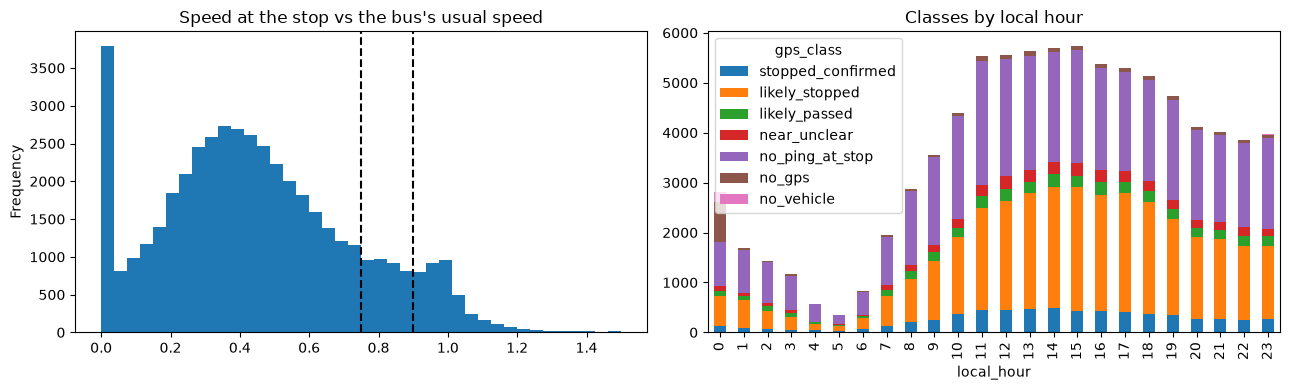

In [10]:
near = stop_gps[stop_gps["n_near"] > 0]
print(f"calls with a ping within {NEAR_M} m of the stop: {len(near):,} of {len(stop_gps):,} ({len(near) / len(stop_gps):.1%})")
print("\nslowest speed (m/s) among the pings at the stop, for those calls:")
print(near["slowest_near_ms"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_string())
print("\nsame as a share of the bus's usual speed:")
print(near["slowest_near_ratio"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
near["slowest_near_ratio"].dropna().clip(upper=1.5).plot(kind="hist", bins=40, ax=ax[0],
                                                         title="Speed at the stop vs the bus's usual speed")
ax[0].axvline(SLOW_RATIO, color="k", ls="--"); ax[0].axvline(FAST_RATIO, color="k", ls="--")
(pd.crosstab(stop_gps["local_hour"], stop_gps["gps_class"]).reindex(columns=ORDER, fill_value=0)
   .plot(kind="bar", stacked=True, ax=ax[1], title="Classes by local hour"))
plt.tight_layout()
plt.show()

In [11]:
# Per stop. These are counts of evidence, not probabilities: a bus that stands still is much more likely to be
# caught by a ping near the stop than one that drives past, so "stopped" is over-represented in these counts.
# Compare stops with each other, do not read the shares as exact.
g = stop_gps.assign(stopped=stop_gps["gps_class"].isin(["stopped_confirmed", "likely_stopped"]),
                    passed=stop_gps["gps_class"].eq("likely_passed")).groupby("stop_id")
per_stop = g.agg(calls=("gps_class", "size"), stopped=("stopped", "sum"), passed=("passed", "sum")).reset_index()
per_stop = per_stop.merge(stops[["stop_id", "stop_name"]], on="stop_id", how="left")
per_stop["conclusive"] = per_stop["stopped"] + per_stop["passed"]
per_stop["passed_share"] = (per_stop["passed"] / per_stop["conclusive"]).round(3)

print("stops where buses most often drove past (at least 10 conclusive calls):")
display(per_stop[per_stop["conclusive"] >= 10].sort_values("passed_share", ascending=False).head(15))


def show_trip(trip_id):
    # call-by-call result of one trip, to check against what you know of the route
    d = stop_gps[stop_gps["trip_id"] == trip_id].sort_values("stop_sequence")
    return d[["stop_sequence", "stop_name", "visit_time", "vehicle_id", "min_dist_m", "n_near", "slowest_near_ms", "slowest_near_ratio", "gps_class"]]


display(show_trip(stop_gps["trip_id"].iloc[0]))

stops where buses most often drove past (at least 10 conclusive calls):


,stop_id,calls,stopped,passed,stop_name,conclusive,passed_share
1398,NSR:Quay:47770,73,1,11,Tankvegen,12,0.917
1242,NSR:Quay:47375,53,1,10,Kanalarmen,11,0.909
1375,NSR:Quay:47721,74,1,9,Mento,10,0.900
976,NSR:Quay:46797,50,2,13,Sothammargeilen,15,0.867
1294,NSR:Quay:47527,54,3,12,Syrinringen,15,0.800
537,NSR:Quay:45781,40,2,8,Norheimsmarka,10,0.800
478,NSR:Quay:45600,107,3,10,Skiftesvik,13,0.769
2136,NSR:Quay:49456,40,4,13,Dovamyrsvegen,17,0.765
2056,NSR:Quay:49242,42,3,9,Grannessletta,12,0.750
975,NSR:Quay:46796,49,4,10,Sothammargeilen,14,0.714


,stop_sequence,stop_name,visit_time,vehicle_id,min_dist_m,n_near,slowest_near_ms,slowest_near_ratio,gps_class
0,14,Hinnasvingene,2026-10-24 00:01:39.315000000+00:00,4120,35.342855,0,NaN,NaN,no_ping_at_stop
1,15,Skråtårnet,2026-10-24 00:04:02.324000000+00:00,4120,8.902423,2,0.641290,0.087759,stopped_confirmed
2,16,Stadionparken,2026-10-24 00:05:10.332000000+00:00,4120,33.799627,0,NaN,NaN,no_ping_at_stop
3,17,Jåttå,2026-10-24 00:06:06.360000000+00:00,4120,1.421303,1,5.487577,0.773439,near_unclear
4,18,Gausel sentrum,2026-10-24 00:07:32.326000000+00:00,4120,12.143230,1,7.086982,0.967038,likely_passed
5,19,Gauselhagen,2026-10-24 00:09:15.290000000+00:00,4120,18.374927,1,3.858310,0.506923,likely_stopped
6,20,Gausel stasjon,2026-10-24 00:11:07.295000000+00:00,4120,2.828140,1,2.156891,0.248931,likely_stopped
7,21,Nådlandsbråtet,2026-10-24 00:11:58.307000000+00:00,4120,40.027290,0,NaN,NaN,no_ping_at_stop
8,22,2020 park,2026-10-24 00:13:42.293000000+00:00,4120,8.095693,1,4.919608,0.616409,likely_stopped
9,23,Løwenstrasse,2026-10-24 00:14:35.311000000+00:00,4120,2.720561,1,3.882246,0.486431,likely_stopped


## 8. Save

In [12]:
keep = ["service_date", "trip_id", "route_id", "route_short_name", "stop_id", "stop_name", "stop_sequence", "occ",
        "sched_no_stop", "visit_time", "vehicle_id", "assign_median_m", "d_at_T_m", "min_dist_m",
        "n_pings_window", "n_near", "n_near_slow", "slowest_near_ms", "slowest_near_ratio", "gps_class", "local_hour"]
stop_gps[keep].to_parquet(OUT_DIR / "stop_gps_status.parquet", index=False)      # one row per observed call + GPS verdict
cmp.to_parquet(OUT_DIR / "stop_event_status.parquet", index=False)               # every scheduled call + what the feed says
assigned.to_parquet(OUT_DIR / "trip_vehicle.parquet", index=False)               # which bus ran which trip
per_stop.to_parquet(OUT_DIR / "per_stop_evidence.parquet", index=False)
print("saved to", OUT_DIR.resolve())

saved to D:\coding\cloud_computing\apis\Entur-Buspulse\tables\parquet_2026-10-24\clean


## Limits

- **30-second pings.** A short dwell can fall between two pings, so `no_ping_at_stop` is a blind spot, not a "passed". Only `likely_passed` is evidence of a bus driving past; absence of `stopped` is not.
- **Standing near a stop is not the same as opening the doors.** A bus held at a red light within `NEAR_M` of a stop looks the same as a bus that stopped. Door-open or passenger-count data would settle it; this dataset has neither.
- **Matching depends on the recorded times.** The bus is found by where it was at the feed's actual times, so calls without an actual time (`unconfirmed`, `cancelled`, not in feed) cannot be tested.
- **Thresholds are judgement.** `NEAR_M`, `SLOW_MS`, `SLOW_RATIO` and `FAST_RATIO` are in the setup cell. They were set on simulated data, so check the histogram in section 7 on the real data and move the dashed lines into the gap between the two groups.